## Exploratory Data Analysis

The data consist of 95 datasets, containing 89 years of SCADA time series distributed
across 36 different WT from the three wind farms A, B, and C. 

The overall dataset is balanced, as 44 out the 95 datasets contain a labeled anomaly event and the other 51 datasets represent normal behavior. The datasets consist of SCADA time series data for each turbine, with a resolution of 10 min. Each dataset includes one year worth of data for training a model, as well as 4 to 98 days of prediction data.

Windfarm A has 86 features, wind farm B has 257 features, and wind farm C has 957 features.

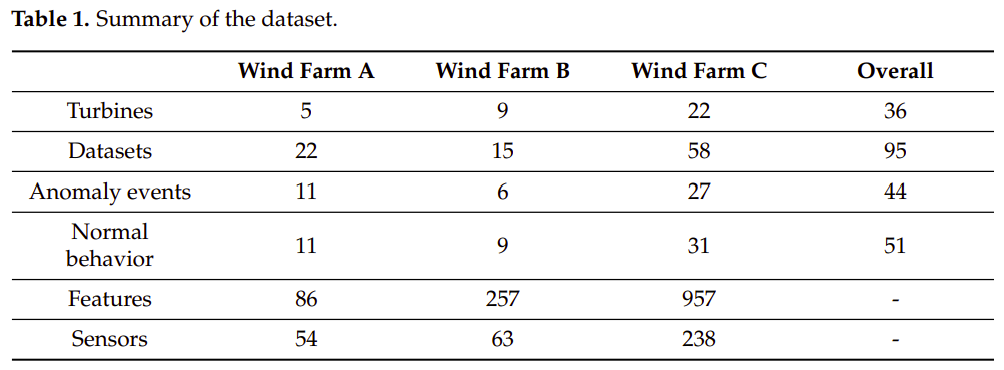

### Data labeling

The data are labeled on two levels. The first level are the so-called event labels. If a dataset contains an anomaly event inside the prediction time frame, the dataset is labeled as an anomaly. If this is not the case, it is labeled as normal.

The second level of labeling assigns a label to each timestamp of every dataset. These labels are called status IDs. The status labels can be used to infer whether a given data point represents normal WT behavior. 

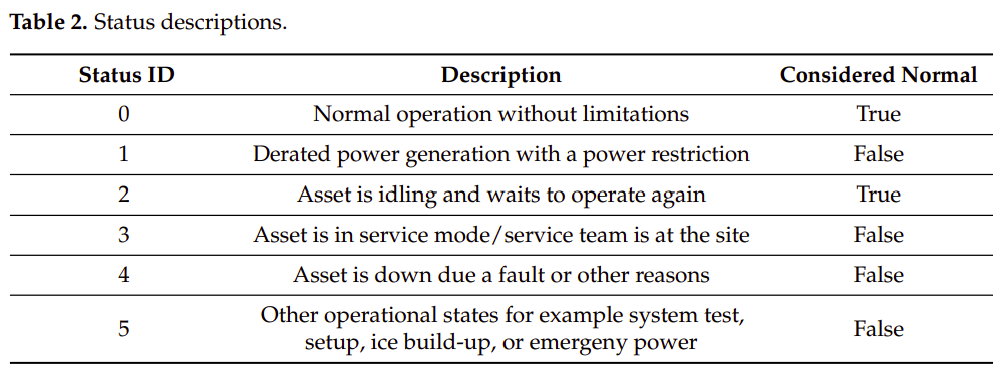

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from energy_fault_detector.evaluation import Care2CompareDataset

c2c = Care2CompareDataset(path="../data/data/CARE_To_Compare", download_dataset=False)

#### Farm events for wind farm A

**event_id** = a datafile holding a year of reading from one turbine <br>
**asset_id** = Which turbine the data comes from. Wind farm A has 5 turbines <br>
**event_label** = Anomaly if the test part leads up to a fault, normal if nothing goes wrong <br>
**event_start** = When the fault window starts <br>
**event_end** = When the fault window ends <br>
**event_description** = What went wrong, for anomaly events. Empty for normal events <br>

In [3]:
events_a = c2c.event_info_all[c2c.event_info_all["wind_farm"] == "A"]
events_a[["event_id", "asset_id", "event_label", "event_description", "event_start", "event_end"]]

,event_id,asset_id,event_label,event_description,event_start,event_end
0,68,11,anomaly,Transformer failure,2023-07-28 13:20:00,2023-08-11 13:10:00
1,22,21,anomaly,Hydraulic group,2023-08-12 09:50:00,2023-08-19 10:00:00
2,72,21,anomaly,Gearbox failure,2023-10-10 08:40:00,2023-10-17 08:40:00
3,73,0,anomaly,Hydraulic group,2023-06-10 11:40:00,2023-06-17 11:40:00
4,0,0,anomaly,Generator bearing failure,2023-08-06 06:10:00,2023-08-20 06:10:00
5,26,0,anomaly,Hydraulic group,2023-10-12 10:20:00,2023-10-19 10:20:00
6,40,10,anomaly,Generator bearing failure,2022-12-26 00:00:00,2023-01-26 13:00:00
7,42,10,anomaly,Hydraulic group,2023-09-09 15:50:00,2023-09-16 15:50:00
8,10,10,anomaly,Gearbox failure,2023-10-11 08:40:00,2023-10-18 08:40:00
9,45,13,anomaly,Hydraulic group,2023-04-19 18:10:00,2023-04-26 18:10:00


### Sensor types

In [5]:
sensors = c2c.feature_descriptions["A"]
sensors

,sensor_name,statistics_type,description,unit,is_angle,is_counter
0,sensor_0,average,Ambient temperature,�C,False,False
1,sensor_1,average,Wind absolute direction,�,True,False
2,sensor_2,average,Wind relative direction,�,True,False
3,wind_speed_3,"maximum,minimum,average,std_dev",Windspeed,m/s,False,False
4,wind_speed_4,average,Estimated windspeed,m/s,False,False
5,sensor_5,"maximum,minimum,std_dev,average",Pitch angle,�,True,False
6,sensor_6,average,Temperature in the hub controller,�C,False,False
7,sensor_7,average,Temperature in the top nacelle controller,�C,False,False
8,sensor_8,average,Temperature in the choke coils on the VCS-section,�C,False,False
9,sensor_9,average,Temperature on the VCP-board,�C,False,False


### Look at one event (event_id = 40)

In [7]:
x_train, x_test = c2c.load_event_dataset(event_id=40, index_column="time_stamp")
print("train:", x_train.shape, " test:", x_test.shape)
print(x_train["status_type_id"].value_counts())
x_train.head()

train: (51219, 57)  test: (4939, 57)
status_type_id
0    43081
4     6842
3     1296
Name: count, dtype: int64


,asset_id,id,status_type_id,Ambient temperature (avg),Wind absolute direction (avg),Wind relative direction (avg),Windspeed (avg),Estimated windspeed (avg),Pitch angle (avg),Temperature in the hub controller (avg),...,Active power - generator disconnected,Active power - generator connected in delta,Active power - generator connected in star,Reactive power - generator disconnected,Reactive power - generator connected in delta,Reactive power - generator connected in star,Total active power,Total reactive power,Rotor rpm (avg),Temperature in the nose cone (avg)
time_stamp,,,,,,,,,,,,,,,,,,,,,
2022-01-01 00:00:00,10,0,0,18.0,220.1,6.1,5.2,5.1,-1.3,27.0,...,0.0,33173.0,0.0,0.0,-13513.0,0.0,33173.0,-13513.0,11.2,19.0
2022-01-01 00:10:00,10,1,0,18.0,218.7,4.7,5.7,5.3,-1.6,27.0,...,0.0,38381.0,0.0,0.0,-15366.0,0.0,38381.0,-15366.0,11.7,19.0
2022-01-01 00:20:00,10,2,0,18.0,216.7,2.7,6.2,5.8,-1.9,27.0,...,0.0,52055.0,0.0,0.0,-15709.0,0.0,52055.0,-15709.0,12.0,19.0
2022-01-01 00:30:00,10,3,0,18.0,197.9,-16.1,6.3,6.2,-1.9,27.0,...,0.0,66365.0,0.0,0.0,-16444.0,0.0,66365.0,-16444.0,12.2,19.0
2022-01-01 00:40:00,10,4,0,18.0,217.2,3.2,6.6,6.1,-2.0,27.0,...,0.0,60980.0,0.0,0.0,-16344.0,0.0,60980.0,-16344.0,12.6,19.0
